In [2]:
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from sys import path

path.insert(0, '/Users/eliezerzucker/Documents/Glickman_Lab/lab_code')

from integrators import (
    perfect_integrator,
    leaky_integrator,
    confirmation_weighted_integrator,
    normative_integrator,
)

from parameters import (
    MU_HIGH, MU_LOW, SIGMA_M, N_FRAMES, K,
    H_VALUES, SIGMA_VALUES,
)


In [13]:
print(SIGMA_VALUES)

[0, 10, 20, 30, 40, 50]


In [13]:
# Simulation parameters — override here if you want a quick run
N_TRIALS = 100000


In [15]:
def run_simulation(h, sigma, n_trials=N_TRIALS, n_frames=N_FRAMES):
    """
    Run all four integrators on n_trials synthetic trials and collect
    accuracy for every model.

    h        : float — the true swap probability used to generate each
               trial's sequence (starting frame 2). This same h is also
               given to normative_integrator as its known hazard rate.
    sigma    : float — internal noise scale
    n_trials : int
    n_frames : int
    returns  : dict with acc_* keys for every model
    """
    model_names = ["perfect", "leaky", "confirmation", "normative"]
    correct = {m: 0 for m in model_names}

    for _ in range(n_trials):
        # --- generate stimulus sequence ---
        left_is_high  = True
        samples_left  = np.zeros(n_frames)
        samples_right = np.zeros(n_frames)

        for t in range(n_frames):
            if t > 0 and np.random.rand() < h:
                left_is_high = not left_is_high
            mu_left  = MU_HIGH if left_is_high else MU_LOW
            mu_right = MU_LOW  if left_is_high else MU_HIGH
            samples_left[t]  = np.random.normal(mu_left,  SIGMA_M)
            samples_right[t] = np.random.normal(mu_right, SIGMA_M)

        d       = samples_left - samples_right
        epsilon = np.random.normal(0, 1, n_frames)   # shared noise draw

        # --- run all models ---
        # normative_integrator is given the true generative h directly —
        # the same h used to drive the switch process above — not an
        # estimate derived from the realized sequence.
        # confirmation_weighted_integrator uses phi = c_hat * sigma,
        # the heuristic slope estimated in the previous cell.
        beliefs = {
            "perfect":      perfect_integrator(d, epsilon, sigma),
            "leaky":        leaky_integrator(d, epsilon, sigma, k=K),
            "confirmation": confirmation_weighted_integrator(d, epsilon, sigma, phi=sigma),
            "normative":    normative_integrator(d, epsilon, sigma, H=h),
        }

        # all models return log-odds-like beliefs — positive means "choose Left"
        chose_left = {m: beliefs[m] > 0 for m in model_names}
        for m, cl in chose_left.items():
            correct[m] += int(cl == left_is_high)

    return {f"acc_{m}": correct[m] / n_trials for m in model_names}

In [16]:
results = {}

for sigma in SIGMA_VALUES:
    for h in H_VALUES:
        print(f"Running sigma={sigma}, H={h} ...")
        results[(sigma, h)] = run_simulation(h, sigma)


Running sigma=0, H=0 ...
Running sigma=0, H=0.1 ...
Running sigma=0, H=0.2 ...
Running sigma=0, H=0.3 ...
Running sigma=10, H=0 ...
Running sigma=10, H=0.1 ...
Running sigma=10, H=0.2 ...
Running sigma=10, H=0.3 ...
Running sigma=20, H=0 ...
Running sigma=20, H=0.1 ...
Running sigma=20, H=0.2 ...
Running sigma=20, H=0.3 ...
Running sigma=30, H=0 ...
Running sigma=30, H=0.1 ...
Running sigma=30, H=0.2 ...
Running sigma=30, H=0.3 ...
Running sigma=40, H=0 ...
Running sigma=40, H=0.1 ...
Running sigma=40, H=0.2 ...
Running sigma=40, H=0.3 ...
Running sigma=50, H=0 ...
Running sigma=50, H=0.1 ...
Running sigma=50, H=0.2 ...
Running sigma=50, H=0.3 ...


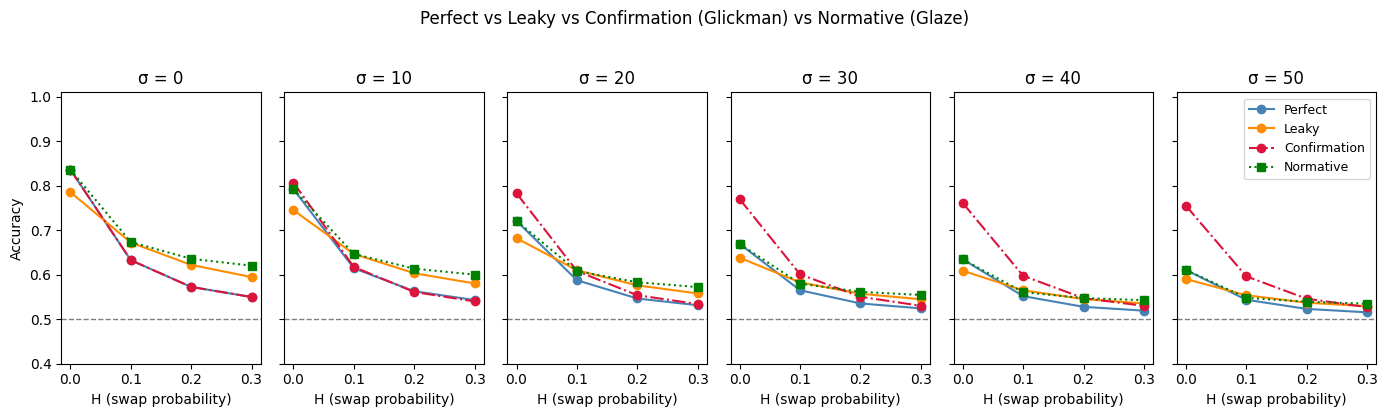

In [17]:
MODELS = [
    ("perfect",      "Perfect",      "steelblue",  "o", "-"),
    ("leaky",        "Leaky",        "darkorange", "o", "-"),
    ("confirmation", "Confirmation", "crimson",    "o", "-."),
    ("normative",    "Normative", "green", "s", ":"),
]

fig, axes = plt.subplots(1, len(SIGMA_VALUES), figsize=(14, 4), sharey='row')

for col, sigma in enumerate(SIGMA_VALUES):

    ax = axes[col]
    for key, label, color, marker, ls in MODELS:
        vals = [results[(sigma, h)][f"acc_{key}"] for h in H_VALUES]
        ax.plot(H_VALUES, vals, color=color, marker=marker,
                linestyle=ls, label=label)
    ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
    ax.set_title(f'σ = {sigma}')
    ax.set_ylim(0.4, 1.01)
    ax.set_xticks(H_VALUES)
    ax.set_xlabel('H (swap probability)')
    if col == 0:
        ax.set_ylabel('Accuracy')
    if col == len(SIGMA_VALUES) - 1:
        ax.legend(fontsize=9)

plt.suptitle(
    'Perfect vs Leaky vs Confirmation (Glickman) vs Normative (Glaze)',
    y=1.03
)
plt.tight_layout()
plt.show()

In [ ]:
# simulation with varying levels of k
# suspect there was a change -> validate with consistency
# if env. is static, use one paradigm
# if env. is dynamic, other paradigm
# start with H = 0 and then tell participants that H has changed
# Run 50 trials at H = 0, then 50 trials at H = .1 (Just for lab)
# Instructions: evidence can flip, breaks after 25 trials
# TODO: experiment ready to run on lab participants

Running sigma=0, k=0.1 ...
Running sigma=0, k=0.3 ...
Running sigma=0, k=0.5 ...
Running sigma=0, k=0.7 ...
Running sigma=0, k=0.9 ...
Running sigma=10, k=0.1 ...
Running sigma=10, k=0.3 ...
Running sigma=10, k=0.5 ...
Running sigma=10, k=0.7 ...
Running sigma=10, k=0.9 ...
Running sigma=30, k=0.1 ...
Running sigma=30, k=0.3 ...
Running sigma=30, k=0.5 ...
Running sigma=30, k=0.7 ...
Running sigma=30, k=0.9 ...
Running sigma=50, k=0.1 ...
Running sigma=50, k=0.3 ...
Running sigma=50, k=0.5 ...
Running sigma=50, k=0.7 ...
Running sigma=50, k=0.9 ...


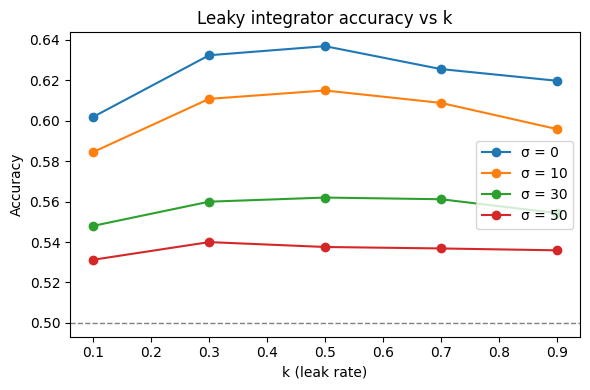

In [14]:
# --- k-sweep: leaky integrator accuracy vs k, across sigma levels ---

SIGMA_VALUES_K = [0, 10, 30, 50]
K_VALUES = [.1, .3, .5, .7, .9]  # 11 values, 0.0 -> 1.0

def run_simulation_leaky_k(k, sigma, h=0.2, n_trials=N_TRIALS, n_frames=N_FRAMES):
    """
    Same trial-generation logic as run_simulation, but only runs the
    leaky integrator, varying k instead of sweeping models.
    """
    correct = 0

    for _ in range(n_trials):
        left_is_high  = True
        samples_left  = np.zeros(n_frames)
        samples_right = np.zeros(n_frames)

        for t in range(n_frames):
            if t > 0 and np.random.rand() < h:
                left_is_high = not left_is_high
            mu_left  = MU_HIGH if left_is_high else MU_LOW
            mu_right = MU_LOW  if left_is_high else MU_HIGH
            samples_left[t]  = np.random.normal(mu_left,  SIGMA_M)
            samples_right[t] = np.random.normal(mu_right, SIGMA_M)

        d       = samples_left - samples_right
        epsilon = np.random.normal(0, 1, n_frames)

        L = leaky_integrator(d, epsilon, sigma, k=k)
        correct += int((L > 0) == left_is_high)

    return correct / n_trials


k_results = {}
for sigma in SIGMA_VALUES_K:
    for k in K_VALUES:
        print(f"Running sigma={sigma}, k={k} ...")
        k_results[(sigma, k)] = run_simulation_leaky_k(k, sigma)


# --- plot ---
fig, ax = plt.subplots(figsize=(6, 4))
for sigma in SIGMA_VALUES_K:
    vals = [k_results[(sigma, k)] for k in K_VALUES]
    ax.plot(K_VALUES, vals, marker='o', label=f'σ = {sigma}')

ax.axhline(0.5, color='gray', linestyle='--', linewidth=1)
ax.set_xlabel('k (leak rate)')
ax.set_ylabel('Accuracy')
ax.set_title('Leaky integrator accuracy vs k')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
# fit the model for each H level seperately
# update the html file to include the sequence we generate (for n = 50 trials)
# higher than 10, lower than 90
# get rid of negative values and decimal places
# we also want to calculate the accuracy of the participants